# XGBoost — Student Dropout

Người thực hiện: **Nguyễn Hoàng Khởi**. Dùng development.csv; chưa đánh giá test.

Kiểm tra boosting trên dữ liệu bảng; so sánh với Random Forest.

Chạy từng cell từ trên xuống. Đóng Excel trước khi chạy. Dùng học kỳ 2 nên không gọi đây là dự đoán lúc nhập học.

## 1. Đọc dữ liệu và cố định thực nghiệm

### 1.1. Khai báo thông tin và thư viện

In [1]:
OWNER = 'Nguyễn Hoàng Khởi'
OWNER_ID = 'khoi'
MODEL_NAME = 'XGBoost'
SCALE_NUMERIC = False

from pathlib import Path
from datetime import datetime
import hashlib
import json
import platform
import uuid
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    make_scorer, recall_score, classification_report,
    ConfusionMatrixDisplay
)

print('Đã nạp thư viện.')

Matplotlib is building the font cache; this may take a moment.


Đã nạp thư viện.


### 1.2. Xác định thư mục dự án và đọc dữ liệu

In [2]:
project_dir = Path.cwd().resolve()

# Nếu đang mở notebook trong thư mục notebooks thì lùi lên thư mục dự án.
if project_dir.name == 'notebooks':
    project_dir = project_dir.parent

data_path = project_dir / 'data' / 'processed' / 'development.csv'

if not data_path.exists():
    raise FileNotFoundError(
        f'Không tìm thấy {data_path}. '
        'Hãy chạy 01_eda.ipynb trước để tạo development.csv.'
    )

data = pd.read_csv(data_path)
data.columns = [' '.join(c.split()) for c in data.columns]

assert not data.columns.duplicated().any()
assert data.isna().sum().sum() == 0, 'Phát hiện missing: cần kiểm tra lại.'

print('Kích thước dữ liệu:', data.shape)
display(data.head())

Kích thước dữ liệu: (3539, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,43,1,9238,1,39,120.0,1,2,1,...,6,10,13,10,11.800000,0,13.9,-0.3,0.79,Graduate
1,1,39,1,9130,1,1,133.1,1,1,1,...,0,5,5,0,0.000000,5,12.7,3.7,-1.70,Dropout
2,1,44,1,9003,1,39,140.0,1,1,38,...,0,6,15,4,10.500000,0,15.5,2.8,-4.06,Enrolled
3,1,16,1,9070,1,1,125.0,1,1,1,...,0,6,6,6,12.833333,0,12.4,0.5,1.79,Graduate
4,1,17,1,9500,1,1,142.0,1,37,37,...,0,8,8,7,14.731429,0,10.8,1.4,1.74,Graduate


### 1.3. Tách đặc trưng, mã hóa nhãn và tạo Cross Validation

In [3]:
X = data.drop(columns='Target')

label_names = ['Dropout', 'Enrolled', 'Graduate']
label_mapping = {label: i for i, label in enumerate(label_names)}

assert set(data['Target'].unique()) == set(label_names)
y = data['Target'].map(label_mapping).astype(int)

print('Mã nhãn:', label_mapping)
print('X:', X.shape, '| y:', y.shape)

DATA_HASH = hashlib.sha256(data_path.read_bytes()).hexdigest()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X, y))

scoring = {
    'accuracy': 'accuracy',
    'macro_f1': 'f1_macro',
    'weighted_f1': 'f1_weighted',
    'recall_dropout': make_scorer(
        recall_score, labels=[0], average='macro', zero_division=0
    )
}

print('SHA256 dữ liệu:', DATA_HASH)
print('Không đọc test.csv. CV chỉ chạy trên development.csv.')

Mã nhãn: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
X: (3539, 36) | y: (3539,)
SHA256 dữ liệu: dfe524288135ecf474ab9b9cf03277f19b818b879cafc176a571aa2a9dbaa690
Không đọc test.csv. CV chỉ chạy trên development.csv.


### 1.4. Tạo thư mục lưu kết quả

In [4]:
experiment_dir = project_dir / 'experiments' / OWNER_ID
figure_dir = project_dir / 'report' / 'figures' / OWNER_ID
model_dir = project_dir / 'models' / OWNER_ID

for directory in [experiment_dir, figure_dir, model_dir]:
    directory.mkdir(parents=True, exist_ok=True)

print('Người thực hiện:', OWNER)
print('Thư mục kết quả:', experiment_dir)
print('Thư mục biểu đồ:', figure_dir)
print('Thư mục mô hình:', model_dir)

Người thực hiện: Nguyễn Hoàng Khởi
Thư mục kết quả: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\khoi
Thư mục biểu đồ: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\report\figures\khoi
Thư mục mô hình: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\models\khoi


## 2. Xây dựng tiền xử lý

### 2.1. Khai báo nhóm đặc trưng

In [5]:
categorical_cols = [
    'Marital status', 'Application mode', 'Course',
    'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation"
]

binary_cols = [
    'Daytime/evening attendance', 'Displaced',
    'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender',
    'Scholarship holder', 'International'
]

numeric_cols = [
    'Application order', 'Previous qualification (grade)',
    'Admission grade', 'Age at enrollment',
    'Unemployment rate', 'Inflation rate', 'GDP'
] + [
    f'Curricular units {semester} sem ({measure})'
    for semester in ['1st', '2nd']
    for measure in [
        'credited', 'enrolled', 'evaluations',
        'approved', 'grade', 'without evaluations'
    ]
]

assigned = categorical_cols + binary_cols + numeric_cols
print('Số đặc trưng khai báo:', len(assigned))

Số đặc trưng khai báo: 36


### 2.2. Kiểm tra và xây dựng Pipeline

In [6]:
assert len(assigned) == len(set(assigned)) == 36
assert set(assigned) == set(X.columns)

for col in binary_cols:
    assert set(X[col].unique()) <= {0, 1}, col

def build_pipeline(estimator):
    processor = ColumnTransformer([
        ('category', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        (
            'numeric',
            StandardScaler() if SCALE_NUMERIC else 'passthrough',
            numeric_cols
        ),
        ('binary', 'passthrough', binary_cols)
    ])

    return Pipeline([
        ('preprocessing', processor),
        ('model', estimator)
    ])

print('Đủ 36 đặc trưng.')
print('Tiền xử lý sẽ được fit riêng trong từng fold.')

Đủ 36 đặc trưng.
Tiền xử lý sẽ được fit riêng trong từng fold.


## 3. Hàm đánh giá và nhật ký Excel

### 3.1. Thiết lập đường dẫn nhật ký

In [7]:
log_path = experiment_dir / 'experiment_history.xlsx'
results = []

print('File nhật ký:', log_path)

File nhật ký: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\khoi\experiment_history.xlsx


### 3.2. Hàm ghi kết quả vào Excel

In [8]:
def save_log(row):
    # Đóng Excel trước khi chạy để tránh PermissionError trên Windows.
    frame = pd.DataFrame([row])

    if log_path.exists():
        old = pd.read_excel(log_path, sheet_name='Runs')
        frame = pd.concat([old, frame], ignore_index=True)

    frame.to_excel(
        log_path,
        sheet_name='Runs',
        index=False,
        engine='openpyxl'
    )
    print('Đã ghi Excel:', log_path)

### 3.3. Hàm chạy đánh giá Cross Validation

In [9]:
def run_cv(estimator, name, note):
    run_id = (
        datetime.now().strftime('%Y%m%d_%H%M%S')
        + '_' + uuid.uuid4().hex[:6]
    )

    scores = cross_validate(
        estimator,
        X,
        y,
        cv=folds,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score='raise'
    )

    details = pd.DataFrame({k: v for k, v in scores.items()})
    details.insert(0, 'fold', range(1, 6))
    details.to_csv(experiment_dir / f'{run_id}_folds.csv', index=False)

    row = {
        'Run_ID': run_id,
        'Timestamp': datetime.now().isoformat(timespec='seconds'),
        'Run_By': OWNER,
        'Model': name,
        'Stage': 'CV fixed configuration',
        'Data_SHA256': DATA_HASH,
        'Samples': len(y),
        'Split': 'development 80%; StratifiedKFold 5; shuffle=True; seed=42',
        'Parameters': json.dumps(
            estimator.get_params(deep=False),
            default=str,
            ensure_ascii=False
        ),
        'Preprocessing': (
            'OneHot categorical; binary passthrough; numeric '
            + ('StandardScaler' if SCALE_NUMERIC else 'passthrough')
        ),
        'Train_Macro_F1': scores['train_macro_f1'].mean(),
        'CV_Macro_F1': scores['test_macro_f1'].mean(),
        'CV_Macro_F1_STD': scores['test_macro_f1'].std(ddof=1),
        'CV_Accuracy': scores['test_accuracy'].mean(),
        'CV_Weighted_F1': scores['test_weighted_f1'].mean(),
        'CV_Recall_Dropout': scores['test_recall_dropout'].mean(),
        'Mean_Fit_Seconds': scores['fit_time'].mean(),
        'Python': platform.python_version(),
        'sklearn': sklearn.__version__,
        'Note': note
    }

    save_log(row)
    results.append(row)

    display(pd.DataFrame([row])[[
        'Model', 'Train_Macro_F1', 'CV_Macro_F1',
        'CV_Macro_F1_STD', 'CV_Accuracy', 'CV_Recall_Dropout'
    ]])

    return scores

## 4. Baseline Dummy

In [10]:
dummy_scores = run_cv(DummyClassifier(strategy='most_frequent'), 'Dummy most frequent', 'Baseline; ignores input features.')

Đã ghi Excel: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\khoi\experiment_history.xlsx


,Model,Train_Macro_F1,CV_Macro_F1,CV_Macro_F1_STD,CV_Accuracy,CV_Recall_Dropout
0,Dummy most frequent,0.222013,0.222013,0.000209,0.499294,0.0


## 5. Mô hình ban đầu

In [11]:
from xgboost import XGBClassifier
model = XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.1,
    objective='multi:softprob', num_class=3, eval_metric='mlogloss',
    tree_method='hist', random_state=42, n_jobs=1)
param_grid = {
    'model__max_depth': [3, 6],
    'model__learning_rate': [0.05, 0.1]
}
initial_scores = run_cv(build_pipeline(model), MODEL_NAME + ' initial',
    'Fixed configuration; no class weighting in this XGBoost experiment.')

Đã ghi Excel: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\khoi\experiment_history.xlsx


,Model,Train_Macro_F1,CV_Macro_F1,CV_Macro_F1_STD,CV_Accuracy,CV_Recall_Dropout
0,XGBoost initial,0.804711,0.706293,0.015629,0.780447,0.765994


### Nhận xét
- Điền số liệu thực tế sau khi chạy.
- So sánh với Dummy, xem chênh lệch train/CV và các lớp dễ nhầm.
- Điểm tuning là điểm lựa chọn; chưa phải đánh giá test độc lập.

## 6. Tinh chỉnh siêu tham số

### 6.1. Khai báo và chạy GridSearchCV

In [12]:
search = GridSearchCV(
    build_pipeline(model),
    param_grid=param_grid,
    scoring='f1_macro',
    cv=folds,
    refit=True,
    n_jobs=1,
    return_train_score=True,
    error_score='raise'
)

started = time.perf_counter()
search.fit(X, y)
elapsed = time.perf_counter() - started

print('Tham số tốt nhất:', search.best_params_)
print('CV Macro-F1 tốt nhất:', round(search.best_score_, 4))
print('Thời gian:', round(elapsed, 2), 'giây')

Tham số tốt nhất: {'model__learning_rate': 0.1, 'model__max_depth': 6}
CV Macro-F1 tốt nhất: 0.7136
Thời gian: 19.65 giây


### 6.2. Lưu bảng kết quả tìm kiếm

In [13]:
search_id = (
    datetime.now().strftime('%Y%m%d_%H%M%S')
    + '_' + uuid.uuid4().hex[:6]
)

search_table = pd.DataFrame(search.cv_results_)
search_table.to_csv(
    experiment_dir / f'{search_id}_grid_search.csv',
    index=False
)

display(search_table[[
    'params', 'mean_train_score', 'mean_test_score',
    'std_test_score', 'rank_test_score'
]].sort_values('rank_test_score'))

,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
3,"{'model__learning_rate': 0.1, 'model__max_dept...",0.970300,0.713649,0.016114,1
1,"{'model__learning_rate': 0.05, 'model__max_dep...",0.916791,0.708949,0.013963,2
2,"{'model__learning_rate': 0.1, 'model__max_dept...",0.804711,0.706293,0.013979,3
0,"{'model__learning_rate': 0.05, 'model__max_dep...",0.751644,0.691357,0.015538,4


### 6.3. Ghi tất cả cấu hình đã thử vào Excel

In [14]:
existing = (
    pd.read_excel(log_path, sheet_name='Runs')
    if log_path.exists()
    else pd.DataFrame()
)

tuning_rows = []

for i, params in enumerate(search.cv_results_['params']):
    tuning_rows.append({
        'Run_ID': f'{search_id}_candidate_{i+1}',
        'Timestamp': datetime.now().isoformat(timespec='seconds'),
        'Run_By': OWNER,
        'Model': MODEL_NAME,
        'Stage': 'GridSearchCV candidate',
        'Data_SHA256': DATA_HASH,
        'Samples': len(y),
        'Split': 'Same development; same 5 folds; seed=42',
        'Parameters': json.dumps(params, ensure_ascii=False),
        'Preprocessing': (
            'OneHot; binary passthrough; numeric '
            + ('StandardScaler' if SCALE_NUMERIC else 'passthrough')
        ),
        'Train_Macro_F1': search.cv_results_['mean_train_score'][i],
        'CV_Macro_F1': search.cv_results_['mean_test_score'][i],
        'CV_Macro_F1_STD': search.cv_results_['std_test_score'][i],
        'Mean_Fit_Seconds': search.cv_results_['mean_fit_time'][i],
        'Python': platform.python_version(),
        'sklearn': sklearn.__version__,
        'Note': 'Điểm dùng chọn tham số; không phải đánh giá test độc lập.'
    })

pd.concat(
    [existing, pd.DataFrame(tuning_rows)],
    ignore_index=True
).to_excel(
    log_path,
    sheet_name='Runs',
    index=False,
    engine='openpyxl'
)

print('Đã lưu mọi cấu hình vào Excel:', log_path)
print('Số cấu hình đã thử:', len(tuning_rows))
print('Lưu ý: best_score_ là điểm chọn tham số, không phải điểm test độc lập.')

Đã lưu mọi cấu hình vào Excel: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\khoi\experiment_history.xlsx
Số cấu hình đã thử: 4
Lưu ý: best_score_ là điểm chọn tham số, không phải điểm test độc lập.


## 7. Phân tích lỗi và so sánh baseline

### 7.1. Tạo dự đoán OOF và báo cáo phân loại

In [15]:
# Mỗi mẫu được dự đoán bởi mô hình không fit trên chính mẫu đó.
oof_pred = cross_val_predict(
    build_pipeline(model),
    X,
    y,
    cv=folds,
    n_jobs=1
)

labels = [0, 1, 2]

report = classification_report(
    y,
    oof_pred,
    labels=labels,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T.round(4)
display(report_df)

report_df.to_csv(
    experiment_dir / 'initial_model_oof_report.csv',
    encoding='utf-8-sig'
)

,precision,recall,f1-score,support
Dropout,0.8295,0.7661,0.7965,1137.0000
Enrolled,0.5714,0.3906,0.4640,635.0000
Graduate,0.7995,0.9298,0.8598,1767.0000
accuracy,0.7804,0.7804,0.7804,0.7804
macro avg,0.7335,0.6955,0.7068,3539.0000
weighted avg,0.7682,0.7804,0.7684,3539.0000


### 7.2. Vẽ ma trận nhầm lẫn

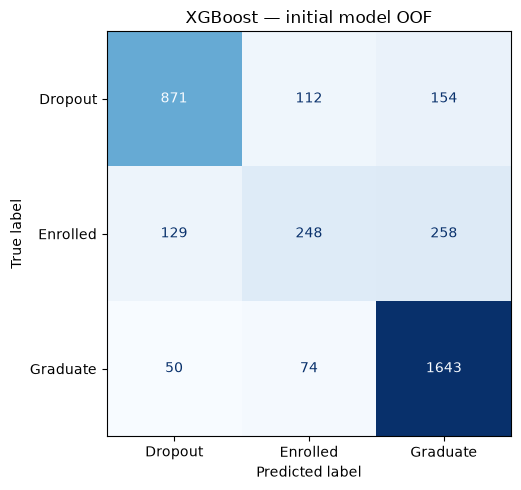

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y,
    oof_pred,
    labels=labels,
    display_labels=label_names,
    ax=ax,
    cmap='Blues',
    colorbar=False
)

ax.set_title(MODEL_NAME + ' — initial model OOF')
fig.tight_layout()
fig.savefig(
    figure_dir / 'initial_model_oof_confusion.png',
    dpi=200
)
plt.show()
plt.close(fig)

### 7.3. Biểu đồ so sánh với Baseline

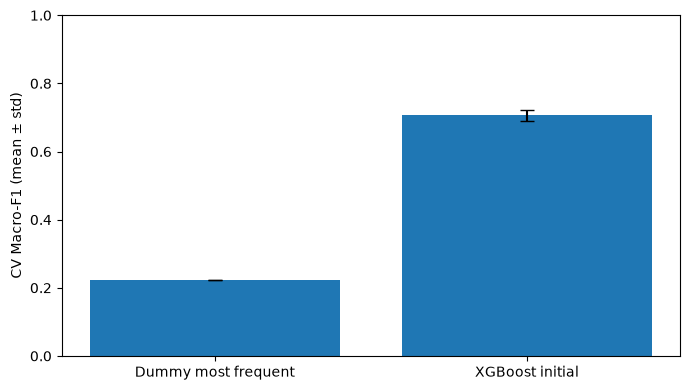

In [17]:
comparison = pd.DataFrame(results).set_index('Model')

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    comparison.index,
    comparison['CV_Macro_F1'],
    yerr=comparison['CV_Macro_F1_STD'],
    capsize=5
)

ax.set_ylim(0, 1)
ax.set_ylabel('CV Macro-F1 (mean ± std)')
fig.tight_layout()
fig.savefig(figure_dir / 'baseline_comparison.png', dpi=200)
plt.show()
plt.close(fig)

### Nhận xét
- Điền số liệu thực tế sau khi chạy.
- So sánh với Dummy, xem chênh lệch train/CV và các lớp dễ nhầm.
- Điểm tuning là điểm lựa chọn; chưa phải đánh giá test độc lập.

## 8. Lưu pipeline ứng viên

### 8.1. Lưu pipeline ứng viên

In [18]:
import joblib

# GridSearchCV đã refit cấu hình tốt nhất trên toàn bộ development.
# Đây là mô hình ứng viên; chưa xác nhận chất lượng trên test.

model_path = model_dir / 'candidate_pipeline.joblib'
joblib.dump(search.best_estimator_, model_path)

print('Đã lưu pipeline ứng viên:', model_path)

Đã lưu pipeline ứng viên: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\models\khoi\candidate_pipeline.joblib


### 8.2. Lưu metadata của mô hình

In [19]:
metadata = {
    'owner': OWNER,
    'model': MODEL_NAME,
    'data_sha256': DATA_HASH,
    'best_params': search.best_params_,
    'selection_cv_macro_f1': search.best_score_,
    'test_evaluated': False,
    'sklearn': sklearn.__version__,
    'label_mapping': label_mapping,
    'feature_columns': X.columns.tolist()
}

metadata_path = model_dir / 'metadata.json'
metadata_path.write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

print('Đã lưu metadata:', metadata_path)
print('Nhật ký Excel:', log_path)
print('Chưa đánh giá test. Nhóm chọn mô hình bằng CV trước.')

Đã lưu metadata: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\models\khoi\metadata.json
Nhật ký Excel: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\khoi\experiment_history.xlsx
Chưa đánh giá test. Nhóm chọn mô hình bằng CV trước.


## 9. Nhật ký tiến độ cá nhân

# Nhật ký tiến độ cá nhân

| **Ngày** | **Công việc** | **Kết quả** | **Khó khăn** | **Bước tiếp theo** |
|---|---|---|---|---|
| 02/11/2026 | Chuẩn bị dữ liệu và tiền xử lý | Hoàn thành Pipeline tiền xử lý | Cần xử lý các loại dữ liệu khác nhau | Huấn luyện mô hình |
| 02/11/2026 | Xây dựng mô hình XGBoost | Hoàn thành mô hình ban đầu | Cần lựa chọn tham số phù hợp | Tinh chỉnh siêu tham số |
| 02/11/2026 | Tối ưu mô hình bằng GridSearchCV | Tìm kiếm cấu hình XGBoost tốt nhất | Thời gian huấn luyện tương đối lâu | Đánh giá mô hình |
| 02/11/2026 | Đánh giá và phân tích lỗi | Hoàn thành báo cáo và ma trận nhầm lẫn | Một số lớp có thể bị dự đoán nhầm | Lưu mô hình |
| 02/11/2026 | Lưu kết quả thực nghiệm | Hoàn thành lưu mô hình và Metadata | Kiểm tra các tệp đầu ra | Hoàn thiện báo cáo |